In [90]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

import pandas as pd
import dask.dataframe as dd

In [91]:
# WITH PHENOTYTPE ONLY
def plot_kymograph(indices, channels, kymo_index, trench_index, headpath, subfolder = "kymograph", prefix = "kymograph", cmap = "gray"):
    file_path = headpath + subfolder + "/" + prefix+"_" + str(kymo_index) + ".hdf5"
    # print(file_path)
    with h5py.File(file_path, "r") as infile:
        # print(infile['mCherry'].shape)
        print(infile.keys())
        # indices = list(range(0, 1, 1))
        # fig, axs = plt.subplots(figsize=(7.5, 10), nrows=1, ncols=len(channels))
        fig, axs = plt.subplots(figsize=(20, 10), nrows=2, ncols=1)
        for i, ch in enumerate(channels):
            img = infile[ch][trench_index][indices[0]]
            for ind in indices[1:]:
                img_ind = infile[ch][trench_index][ind]
                img = np.concatenate((img, img_ind), axis=1)
            axs[i].imshow(img, cmap=cmap, aspect=1)
            # Annotate kymo and trench index
            # axs[i].text(10, 10, f"Kymo: {kymo_index}, Trench: {trench_index}", color="w")
            axs[i].set_title(ch)
            # _= plt.figure(figsize=(5, 5))
            # _ = plt.imshow(img, cmap=cmap, aspect=1)
            # Annotate kymo and trench index
        _= plt.text(10, 10, f"Kymo: {kymo_index}, Trench: {trench_index}", color="w")
        _=plt.show()
        _=plt.close()

indices = np.arange(0,15)
def update_plot(kymo_index, trench_index):
    # y = np.sin(frequency * x)
    _ = plt.clf()  # Clear the previous plot
    channels = ["BF","RFP", "Cy5"]
    plot_kymograph(indices, channels, kymo_index, trench_index, headpath, subfolder = "kymograph", prefix = "kymograph", cmap='gray')
    _ = plt.show()
    # channels = ["data"]
    # plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "fluorsegmentation", prefix="segmentation", cmap="jet")
    # _ = plt.show()

# Create an interactive slider widget
trench_index_slider = widgets.IntSlider(min=0, max=149, step=1, value=0)
kymo_index_slider = widgets.IntSlider(min=0, max=500, step=1, value=0)

In [92]:
# WITH SEGMENTATION

import h5py
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

def plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "kymograph", prefix = "kymograph", cmap = "gray"):
    file_path = headpath + subfolder + "/" + prefix+"_" + str(kymo_index) + ".hdf5"
    # print(file_path)
    with h5py.File(file_path, "r") as infile:
        # print(infile['mCherry'].shape)
        # indices = list(range(0, 1, 1))

        for ch in channels:
            img = infile[ch][trench_index][indices[0]]
            for ind in indices[1:]:
                img_ind = infile[ch][trench_index][ind]
                img = np.concatenate((img, img_ind), axis=1)
            _= plt.figure(figsize=(20,40))
            if ch == 'mCherry':
                _ = plt.imshow(img, cmap=cmap, aspect=1, vmin=400, vmax=3000)
            else:
                _ = plt.imshow(img, cmap=cmap, aspect=1)
            # Annotate kymo and trench index
            _= plt.text(10, 10, f"Kymo: {kymo_index}, Trench: {trench_index}", color="w")
            _=plt.show()
            _=plt.close()

indices = np.arange(0, 61)
# Create a function to update the plot
def update_plot(trench_index, kymo_index):
    # y = np.sin(frequency * x)
    _ = plt.clf()  # Clear the previous plot
    channels = ["mCherry"]
    plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "kymograph", prefix = "kymograph", cmap='gray')
    channels = ['data']
    plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "fluorsegmentation", prefix = "segmentation", cmap='jet')
    _ = plt.show()
    # channels = ["data"]
    # plot_kymograph(indices, channels, trench_index, kymo_index, headpath, subfolder = "fluorsegmentation", prefix="segmentation", cmap="jet")
    # _ = plt.show()

# Create an interactive slider widget
# trench_index_slider = widgets.IntSlider(min=0, max=149, step=1, value=0)
# kymo_index_slider = widgets.IntSlider(min=0, max=500, step=1, value=0)

In [93]:
HEADPATH = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/'
headpath_barcodes = HEADPATH + '/Barcodes/'
headpath_phenotype = HEADPATH + '/Growth_Division/'

# Load hdf5 metadata
fov_metadata_barcodes = (pd
                .read_hdf(headpath_barcodes + 'metadata.hdf5')
                .loc[:,0, :])
# fov_metadata # only timepoint 0

# open barcode df

df_fish = pd.read_hdf(headpath_barcodes+'/2025-07-06_barcode_output_df_fiducials_hamming-1_rm-4-17-25-27.hdf5')
# df_fish

# Open kymograph metadata
kymo_metadata_barcodes = (
    dd.read_parquet(
    headpath_barcodes+'/kymograph/metadata',
    engine='pyarrow',
    # Load only these columns: ['File Index', 'File Trench Index', 'trenchid']
    columns=['File Index', 'File Trench Index', 'trenchid', 'fov', 'y (local)', 'x (local)', 'lane orientation', 'timepoints']
    )
    .compute()
    .groupby('trenchid')
    .first()
)

# For phenotypes!
# Load hdf5 metadata
fov_metadata_phenotype = (pd
                .read_hdf(headpath_phenotype + 'metadata.hdf5')
                .loc[:,60, :]
                .loc[:, ['File Index', 'Image Index']]
                .rename(columns={'File Index': 'File Index Phenotype', 'Image Index': 'Image Index Phenotype'})
                )
# fov_metadata # only timepoint 0


In [94]:
df_fish

,trenchid,Barcode Signal,Barcode,consensus,reference,alignmentstart,cigar,subsample,barcode depth,closest_match,...,locus_tag,offset,Gene,sgRNA Sequence,Target Sequence,Category,Predicted_Efficacy,TargetID,barcode,barcodeid
0,432,"[1914.08, 1844.04, 8797.1, 1927.0, 1899.04, 18...",001000100000110010100100001010,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,547M1D543M,NaN,90.0,3,...,BSU_11210,272.0,argB,CGCGGCTCGCAGTCCGTCTT,AACACGGACTGCGAGCCGCG,auxotroph,0.571329,2073.0,000100100111000100101010000010,36831
1,1527,"[4333.04, 3262.14, 6478.0599999999995, 6434.45...",111110111001011000111111000110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,885M1D205M,NaN,175.0,3,...,BSU_28990,442.0,dnaB,TCGCATCTTCTGAAATGGCC,GGCCATTTCAGAAGATGCGA,essential,1.000000,1534.0,110001110101101110111101101010,306470
2,1592,"[6364.18, 1674.02, 1761.04, 1666.0, 1681.0, 16...",100000111001010100111001001110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,823M1D267M,NaN,14927.0,2,...,BSU_28140,114.0,hemD,GCGGCGAAACGTAATCAACG,CTTTGATTACGTTTCGCCGC,essential,0.409729,1454.0,101001000101001100110011101010,247354
3,3425,"[1561.08, 1558.02, 1613.0, 1608.02, 1535.02, 1...",000000000000010000110000000101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,145.0,3,...,BSU_15920,113.0,acpA,AACAAGCTCAACTACATCCA,TAGATGTAGTTGAGCTTGTT,essential,0.284068,823.0,000000000101001000000001000001,10757
4,5066,"[1769.08, 1734.08, 7928.619999999999, 1790.04,...",001010110000110000001110001011,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,267.0,4,...,BSU_15980,108.0,ffh,CAGCCTCAAGCAGCGCTAGA,TCTTGCGCTGCTTGAGGCTG,essential,0.754849,850.0,000000100011100100111110000011,13511
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127018,1128910,"[2026.04, 2468.24, 4144.12, 4241.28, 1998.02, ...",011100101000001100100110001101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,1192.0,2,...,BSU_15160,514.0,pbpB,TTAGATGCAAATACTCCGTG,AACGGAGTATTTGCATCTAA,essential,0.193834,694.0,011000110100000010101111100001,143520
127019,1130047,"[4283.5199999999995, 3032.2, 1910.08, 6509.379...",110111010001110111101001000001,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,351.0,2,...,BSU_tRNA_62,7.0,trnB-Met3,GCTCTAACCAACTGAGCTAT,TTAGCTCAGTTGGTTAGAGC,tRNA,0.349635,2405.0,111101011111110100010000001001,387001
127020,1131965,"[4503.0599999999995, 2255.06, 4024.06, 2330.06...",111010110000111001110111001010,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,120.0,3,...,BSU_06020,103.0,groES,GCCACGATTTTGCCCTCTTG,CAAGAAGGCAAAATCGTGGC,essential,0.531552,484.0,100000101111101010111110001010,207452
127021,1131998,"[2020.06, 2540.02, 4457.44, 4312.2, 2072.0, 20...",011100000000011100110011001111,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,489M1D601M,NaN,191.0,3,...,BSU_01110,265.0,rpsG,CGTTCAGGACGAACTTCTAG,GTAGAAGTTCGTCCTGAACG,essential,0.303747,207.0,011000110101001010000111001011,159282


In [95]:
# Open kymograph metadata
kymo_metadata_phenotype = (
    dd.read_parquet(
    headpath_phenotype+ '/kymograph/metadata',
    engine='pyarrow',
    # Load only these columns: ['File Index', 'File Trench Index', 'trenchid']
    columns=['File Index', 'File Trench Index', 'trenchid', 'fov', 'y (local)', 'x (local)', 'lane orientation', 'timepoints']
    )
    .compute()
    .groupby('trenchid')
    .last()
)

In [96]:
lookup_metadata = (
kymo_metadata_barcodes.merge(
    fov_metadata_phenotype,
    left_on='fov',
    right_index=True,
    )
    .merge(df_fish.loc[:,['trenchid', 'opLAG1_id','Gene', 'Barcode', 'barcode']],
           left_index=True,
           right_on='trenchid',)
    .set_index('trenchid')
)

In [97]:
lookup_metadata

,File Index,File Trench Index,fov,y (local),x (local),lane orientation,timepoints,File Index Phenotype,Image Index Phenotype,opLAG1_id,Gene,Barcode,barcode
trenchid,,,,,,,,,,,,,
0,0,0,0,20.342777,2.224991,bottom,0,1,10,1183.0,rpsK,010000001000100111011100001000,011100001010001100001010100000
12,0,12,0,20.342777,43.546256,bottom,0,1,10,1027.0,rplR,010110001000111001101001001100,000000011111100110000011101000
24,0,24,0,20.342777,84.867521,bottom,0,1,10,2324.0,ileS,100000010000000000001111000000,100001000000000100011100001000
42,0,42,0,20.342777,146.743467,bottom,0,1,10,6829.0,hisC,101100001001111010100000001101,100101110111000010000011100001
45,0,45,0,20.342777,156.914856,bottom,0,1,10,1620.0,ligA,010100101000100100001001001111,011000010010000100100011101011
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1132423,1700,223,626,567.054900,33.798676,top,0,1253,10,2256.0,murB,101000111001011001000100001000,100001101001100010111010100000
1132426,1700,226,626,567.054900,44.181968,top,0,1253,10,6709.0,gltC,000101110000101111111001001010,001100011110011110110010001010
1132436,1700,236,626,567.054900,78.510404,top,0,1253,10,2626.0,rpsP,110111110000101000110010001000,110000010110111010110110000000


In [130]:
# opLAG1_id = 287 # divIC
# opLAG1_id = 2244 # murG
# opLAG1_id = 1221 # rplQ
# opLAG1_id = 2111 # ftsW
# opLAG1_id = 2104 # ftsW
opLAG1_id = 849 # rplP
# opLAG1_id = 732 # rplD
# opLAG1_id = 2324.0 #ileS
# ALIGNMENT ERROR IN: 2324, 7
lookup_grna = lookup_metadata[lookup_metadata['opLAG1_id']==opLAG1_id]
lookup_grna

,File Index,File Trench Index,fov,y (local),x (local),lane orientation,timepoints,File Index Phenotype,Image Index Phenotype,opLAG1_id,Gene,Barcode,barcode
trenchid,,,,,,,,,,,,,
36443,54,479,20,64.842601,140.174446,top,0,41,10,849.0,rplP,010000101000010111111111000001,001100001101001100101100101001
151024,226,508,83,275.687005,172.807650,bottom,0,167,10,849.0,rplP,111010101000010011010001000101,100100101001101000100001101001
360757,541,451,199,190.289724,248.033543,top,0,399,10,849.0,rplP,100100001000111101111001000001,001000011111001110000000101001
428050,642,478,236,317.220174,168.993379,top,0,473,10,849.0,rplP,100100001000111101111001000001,001000011111001110000000101001
530572,796,436,293,145.789900,60.074762,bottom,0,587,10,849.0,rplP,100011001001101101001101001100,101001001010110110001011101000
654353,982,341,361,400.074608,67.491400,bottom,0,723,10,849.0,rplP,101000100000100000001010000011,100000100010000100100100000011
663539,996,203,366,399.438896,440.442306,bottom,0,733,10,849.0,rplP,010000101000010111111111000001,001100001101001100101100101001
1079751,1621,165,597,398.591281,38.672466,bottom,0,1195,10,849.0,rplP,111111100001111000000110001110,110001010011110010101111000010


(2960, 2960)


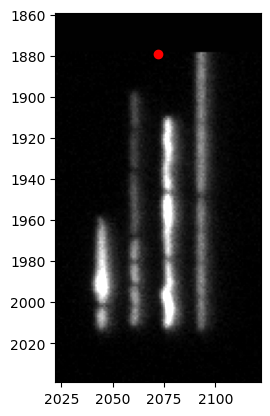

In [154]:
# ONLY PHENOTYPE
index = 6

bc_kymo_file_index = lookup_grna.iloc[index]['File Index']
bc_kymo_trench_index = lookup_grna.iloc[index]['File Trench Index']
bc_fov = lookup_grna.iloc[index]['fov']

y_local_microns = lookup_grna.iloc[index]['y (local)']
x_local_microns = lookup_grna.iloc[index]['x (local)']

ph_fov_file_index = lookup_grna.iloc[index]['File Index Phenotype']
ph_fov_image_index = lookup_grna.iloc[index]['Image Index Phenotype']
fov_file_index = ph_fov_file_index
fov_index_in_file = ph_fov_image_index

delta_x = 50
delta_y_feeding = 20
delta_y_trench = 140+20
pixel_size = 0.2125  # microns_per_pixel

y_local = int(y_local_microns/pixel_size)
x_local = int(x_local_microns/pixel_size)

with h5py.File('/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/Growth_Division/hdf5/hdf5_'+str(fov_file_index)+'.hdf5', "r") as infile:

    img = infile['mCherry'][fov_index_in_file]
    print(img.shape)
    plt.plot(x_local, y_local, 'ro')  # Plot the point in red
    plt.imshow(img,
    # # plt.imshow(infile['data'][y_local-delta_y:y_local+delta_y, x_local-delta_x:x_local+delta_x],
    cmap='gray', aspect = 1, vmin = 400, vmax= 3000)
    plt.xlim([np.max([x_local - delta_x, 0]), np.min([x_local+delta_x, 2960])])
    plt.ylim([np.max([y_local - delta_y_feeding, 0]),np.min([y_local+delta_y_trench, 2960])])
    plt.gca().invert_yaxis()

In [155]:
print('FOV', bc_fov)
print('x_local (microns):', x_local_microns)
print('y_local (microns):', y_local_microns)
# Get phenotype kymograph!
distances = (
    kymo_metadata_phenotype
    .loc[lambda df_:df_['fov'] == bc_fov]
    .assign(
        distance_sq = lambda df_: (df_['y (local)'] - y_local_microns)**2 + (df_['x (local)'] - x_local_microns)**2
    )
    .sort_values('distance_sq', ascending=True)
)

ph_kymo_file_index = distances.iloc[0]['File Index']
ph_kymo_trench_index = distances.iloc[0]['File Trench Index']

distances.head(5)

FOV 366
x_local (microns): 440.442305598733
y_local (microns): 399.43889634525465


,File Index,File Trench Index,fov,y (local),x (local),lane orientation,timepoints,distance_sq
trenchid,,,,,,,,
205173,1258,119,366,401.625,442.10625,bottom,60,7.547760
205172,1258,118,366,401.625,438.70625,bottom,60,7.792938
205171,1258,117,366,401.625,435.30625,bottom,60,31.158116
205174,1258,120,366,401.625,445.71875,bottom,60,32.619915
205175,1258,121,366,401.625,455.91875,bottom,60,244.299380


In [156]:
headpath = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/Growth_Division/'

<Figure size 640x480 with 0 Axes>

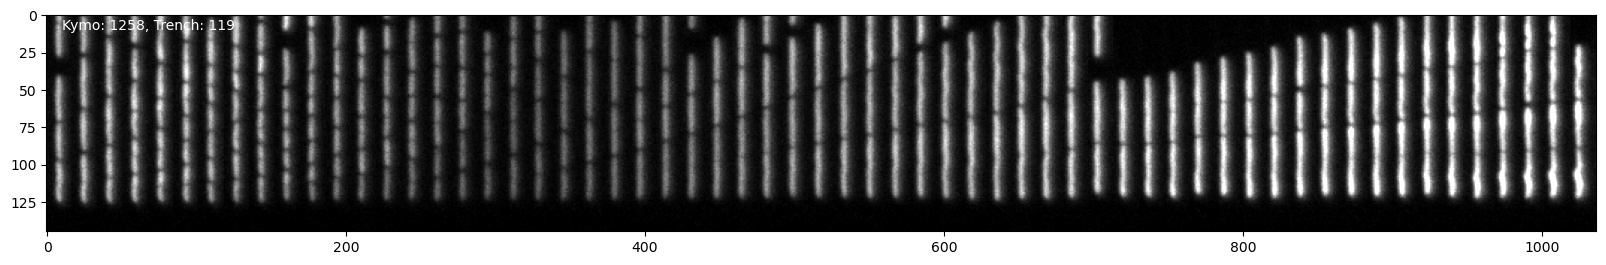

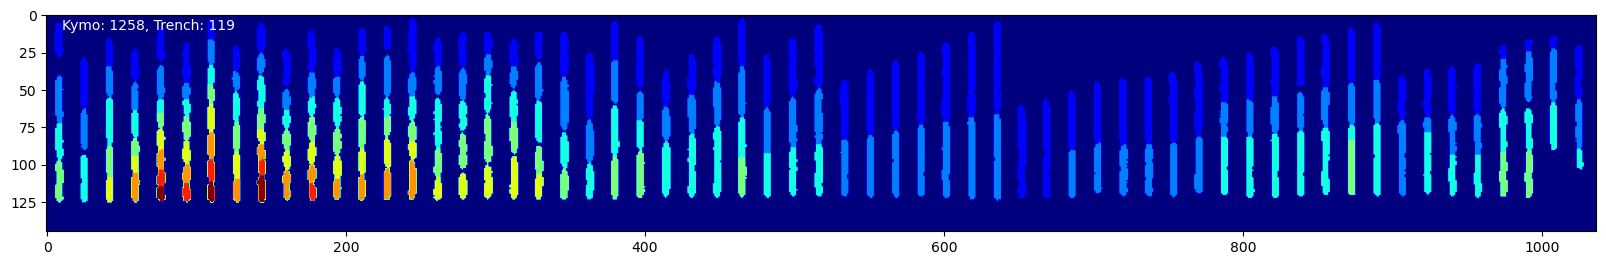

In [158]:
indices = np.arange(0,61)
update_plot(ph_kymo_trench_index, ph_kymo_file_index)

<KeysViewHDF5 ['mCherry']>


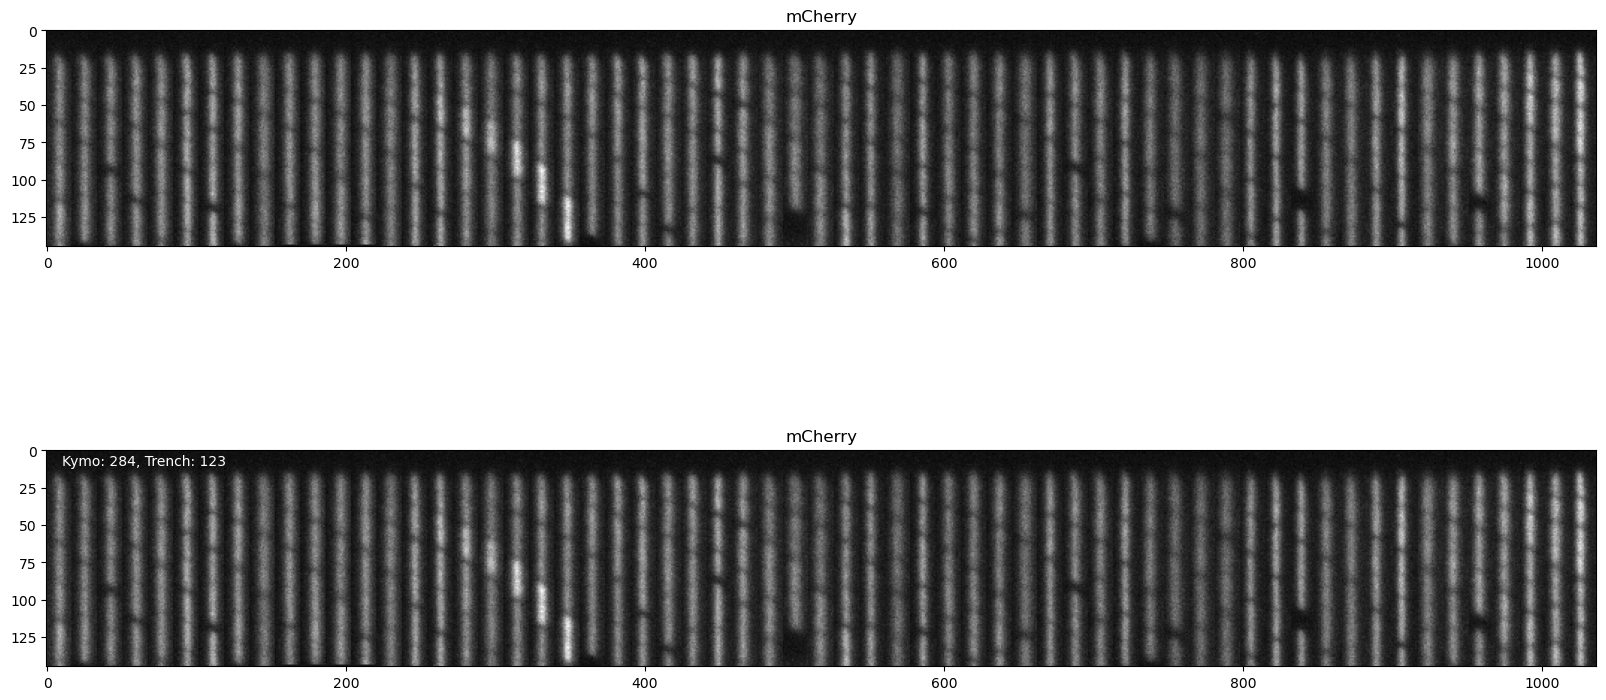

In [12]:
# PHENOTYPE ONLY
# ph_kymo_file_index = distances.iloc[0]['File Index']
# ph_kymo_trench_index = distances.iloc[0]['File Trench Index']

# headpath = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/Growth_Division/'
# plot_kymograph(indices=np.arange(0,61,1),
#                channels=["mCherry", "mCherry"],
#                kymo_index = ph_kymo_file_index,
#                trench_index= ph_kymo_trench_index,
#                headpath=headpath_phenotype, subfolder="kymograph", prefix="kymograph", cmap='gray'
#                )

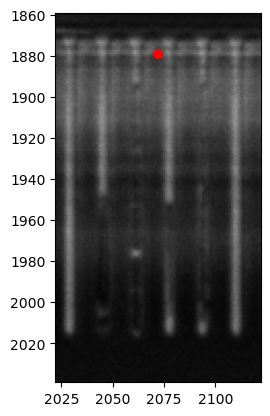

In [159]:
with h5py.File('/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/run/' + 'fov='+str(bc_fov)+'_config=BF_t=0.hdf5', "r") as infile:
    plt.plot(x_local, y_local, 'ro')  # Plot the point in red
    plt.imshow(infile['data'],
    # plt.imshow(infile['data'][y_local-delta_y:y_local+delta_y, x_local-delta_x:x_local+delta_x],
    cmap='gray', aspect = 1)
    plt.xlim([np.max([x_local - delta_x, 0]), np.min([x_local+delta_x, 2960])])
    plt.ylim([np.max([y_local - delta_y_feeding, 0]),np.min([y_local+delta_y_trench, 2960])])
    plt.gca().invert_yaxis()

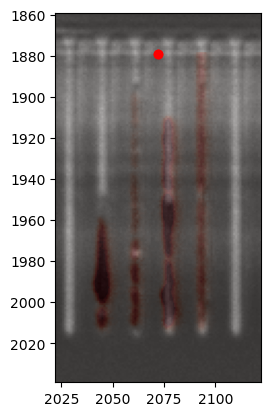

In [160]:
with h5py.File('/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/run/' + 'fov='+str(bc_fov)+'_config=BF_t=0.hdf5', "r") as infile:
    plt.plot(x_local, y_local, 'ro')  # Plot the point in red
    plt.imshow(infile['data'],
    # plt.imshow(infile['data'][y_local-delta_y:y_local+delta_y, x_local-delta_x:x_local+delta_x],
    cmap='gray', aspect = 1)
    plt.xlim([np.max([x_local - delta_x, 0]), np.min([x_local+delta_x, 2960])])
    plt.ylim([np.max([y_local - delta_y_feeding, 0]),np.min([y_local+delta_y_trench, 2960])])
    plt.gca().invert_yaxis()

with h5py.File('/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/Growth_Division/hdf5/hdf5_'+str(fov_file_index)+'.hdf5', "r") as infile:

    img = infile['mCherry'][fov_index_in_file]
    plt.plot(x_local, y_local, 'ro')  # Plot the point in red
    plt.imshow(img,
    # # plt.imshow(infile['data'][y_local-delta_y:y_local+delta_y, x_local-delta_x:x_local+delta_x],
    cmap='Reds', aspect = 1, vmin = 500, vmax= 2500, alpha=0.2)
    plt.xlim([np.max([x_local - delta_x, 0]), np.min([x_local+delta_x, 2960])])
    plt.ylim([np.max([y_local - delta_y_feeding, 0]),np.min([y_local+delta_y_trench, 2960])])
    plt.gca().invert_yaxis()


In [149]:
indices = np.arange(0,15)

In [161]:
headpath = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/Barcodes/'
indices
plot_kymograph(indices,
               channels=["BF", "RFP"],
            #    channels=["BF", "RFP", "Cy5"],
               kymo_index = bc_kymo_file_index,
               trench_index=bc_kymo_trench_index,
               headpath=headpath_barcodes, subfolder="kymograph", prefix="kymograph", cmap='gray'
               )


IndexError: index 15 is out of bounds for axis 0 with size 15

In [162]:
### QC segmentation
import h5py
import matplotlib.pyplot as plt
import numpy as np
TRENCH_WIDTH = 9 # TODO GENERALIZE
def show_kymograph(
        path_prefix,
        path_kymo_dir_prefix,
        channels,
        cmap,
        kymo_file_index,
        trench_index,
        t_indices,
        figsize,
        Barcode = None,
        barcode_phe = None #translated from seq barcode
        ):
    
    n_cycles_per_ch = 15 # TODO GENERALIZE
    with h5py.File(path_prefix + path_kymo_dir_prefix + str(kymo_file_index) + ".hdf5", "r") as infile:
        for i_ch, ch in enumerate(channels):
            img = infile[ch][trench_index][t_indices[0]]
            for ind in t_indices[1:]:
                img_ind = infile[ch][trench_index][ind]
                img = np.concatenate((img, img_ind), axis=1)
            plt.figure(figsize=figsize)
            # Do not show axes ticks
            plt.xticks([])
            plt.yticks([])
            plt.imshow(img, cmap=cmap, aspect=1)
            # Annotate the kymo_file_index and the trench index at the bottom left corner
            plt.annotate(f'kymo_file_index: {kymo_file_index}, trench index: {trench_index}', (10, 15), color='white')
            # Annotate the cycle number at the bottom of each slice
            for i, ind in enumerate(t_indices):
                plt.annotate(f'{ind}', (i*TRENCH_WIDTH+TRENCH_WIDTH/4, 160), color='white', fontsize=8) # 13 is the width of a slice
            
            # Annotate the Barcode bit at the bottom of each slice
            if Barcode is not None:
                
                for i, bit in enumerate(Barcode[i_ch*n_cycles_per_ch:(i_ch+1)*n_cycles_per_ch]):
                    plt.annotate(f'{bit}', (i*TRENCH_WIDTH+TRENCH_WIDTH/4, 140), color='yellow', fontsize=8) # 13 is the width of a slice

            # Annotate the barcode bit at the bottom of each slice
            if barcode_phe is not None:
                for i, bit in enumerate(barcode_phe[i_ch*n_cycles_per_ch:(i_ch+1)*n_cycles_per_ch]):
                    plt.annotate(f'{bit}', (i*TRENCH_WIDTH+TRENCH_WIDTH/4, 120), color='red', fontsize=8) # 13 is the width of a slice

            plt.show()
            plt.close()

In [163]:
def map_bc_to_pheno(barcode,
                    cycleorder = [0,1,6,7,12,13,18,19,24,25,4,5,10,11,16,
                                  2,3,8,9,14,15,20,21,26,27,17,22,23,28,29],
                    ):
    barcode_phe = [-1]*30
    for i, bit in enumerate(barcode):
        # print(i, bit)
        # Find the position of i in cycleorder
        i_phe = cycleorder.index(i)
        barcode_phe[i_phe] = bit
    barcode_phe = ''.join(barcode_phe)
    return barcode_phe

In [164]:
Barcode, barcode = lookup_grna.iloc[index][['Barcode', 'barcode']]
barcode_phe = map_bc_to_pheno(barcode)

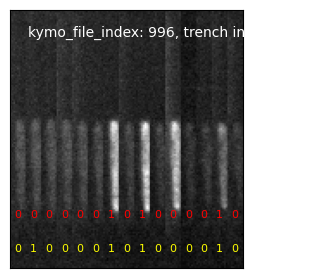

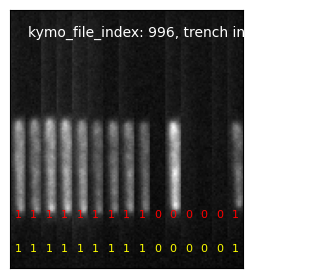

In [165]:
figsize = (3, 6)
path_prefix = "/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/Barcodes/"
path_kymo_dir_prefix = "kymograph/kymograph_"
# channels = ["BF", "RFP", "Cy5"]
channels = ["RFP", "Cy5"]
cmap = "gray"
t_indices = np.arange(0,15)
show_kymograph(path_prefix, path_kymo_dir_prefix, channels, cmap, bc_kymo_file_index, bc_kymo_trench_index, t_indices, figsize, Barcode, barcode_phe)